In [6]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'dashboard/app.py').is_file():
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data'
HW_DATA_DIR = ROOT / 'HW/data'

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Подготовка таблицы

In [7]:
df_pedagog1 = pd.read_excel(DATA_DIR / 'Педагоги.xlsx', sheet_name='2022')
df_pedagog1['year']=2022

df_pedagog2 = pd.read_excel(DATA_DIR / 'Педагоги.xlsx', sheet_name='2023')
df_pedagog2['year']=2023

df_pedagog3 = pd.read_excel(DATA_DIR / 'Педагоги.xlsx', sheet_name='2024')
df_pedagog3['year']=2024

df_pedagog_all = pd.concat([df_pedagog1, df_pedagog2, df_pedagog3], axis=0)

In [8]:
df_pedagog_all = df_pedagog_all.rename(columns={'ID образовательной организации':'school_num',
                                                'Основная должность':'main_position',
                                                'Направление деятельности':'speciality',
                                                'Пол': 'sex',
                                                'Возраст':'age',
                                                'Ученая степень':'academic_degree',
                                                'Квалификационная категория (педагогического работника)':'category_qual',
                                                'Дата присвоения квалификационной категории':'category_date',
                                                'Срок действия квалификационной категории':'category_due',
                                                'Общий стаж работы':'experience_age_all',
                                                'Стаж педагогической работы':'experience_age_pedagogic',
                                                'Предмет':'subject',
                                                'Параллель':'parallel',
                                                'Имеет классное руководство':'class_manager'})

keywords = ['педагог', 'учитель', 'методист', 'преподават', 'воспитатель', 'тьютор']
matching_pedagog = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords)])
matching_pedagog = set([item for item in matching_pedagog if 'заместитель' not in str(item).lower()])

keywords_manager = ['заместитель', 'ведущий', 'заведующий', 'руководитель', 'начальник', 'главный']
matching_manager = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords_manager)])

matching_other = set(df_pedagog_all.main_position.unique()).difference(matching_pedagog.union(matching_manager))

In [9]:
matching_dict = {}

for val in matching_pedagog:
    matching_dict[val] = 'учитель'
for val in matching_manager:
    matching_dict[val] = 'руководитель'
for val in matching_other:
    matching_dict[val] = 'другой'

In [10]:
df_pedagog_all['main_position_cat'] = df_pedagog_all['main_position'].map(matching_dict).fillna('не_найдено')

In [11]:
df_pedagog_all['sex'] = df_pedagog_all['sex'].map({'Мужской': 1, 'Женский': 0})

In [12]:
keywords = {'кандидат': 'кандидат', 'доктор': 'доктор'}

def find_academic_degree(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

df_pedagog_all['academic_degree_cat'] = df_pedagog_all['academic_degree'].apply(find_academic_degree)

In [13]:
keywords = {'высшая': 'высшая', 'первая': 'первая', 'вторая': 'вторая'}

def find_category_qual(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

# Применяем функцию
df_pedagog_all['category_qual_cat'] = df_pedagog_all['category_qual'].apply(find_category_qual)

In [14]:
df_pedagog_all['category_date'] = df_pedagog_all['category_date'].astype('Int64')
df_pedagog_all['category_due'] = df_pedagog_all['category_due'].astype('Int64')

In [15]:
df_pedagog_all['category_active'] = df_pedagog_all.apply(lambda row: "не было" if pd.isna(row['category_due']) # Если нет данных
                                    else ("активно" if pd.to_datetime(row['category_due']) > pd.to_datetime(row['year']) # Если текущий год меньше года действия
                                    else "не активно"), axis=1)

In [16]:
df_pedagog_all['experience_age_other'] = df_pedagog_all.experience_age_all - df_pedagog_all.experience_age_pedagogic

In [17]:
df_pedagog_all['n_unique_subjects'] = (
    df_pedagog_all.groupby(['year', 'id'])['subject'].transform('nunique')
)

In [18]:
df_pedagog_all['min_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('min')
)

In [19]:
df_pedagog_all['max_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('max')
)

In [20]:
df_pedagog_all['n_unique_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('nunique')
)

In [21]:
df_pedagog_all['class_manager'] = df_pedagog_all['class_manager'].map({'Да': 1, 'Нет': 0})

In [22]:
df_pedagog_all = df_pedagog_all.sort_values(['id', 'year'])
df_pedagog_all['max_year'] = df_pedagog_all.groupby('id')['year'].transform('max')
df_pedagog_all['is_out_next_year'] = (df_pedagog_all['year'] == df_pedagog_all['max_year']).astype(int)
df_pedagog_all = df_pedagog_all.drop(columns=['max_year'])

In [23]:
RULES = {
    'учитель': [
        'английского языка', 'русского языка', 'французского языка',
        'немецкого языка', 'испанского языка', 'итальянского языка',
        'китайского языка', 'арабского языка', 'родного языка',
        'родной литературы', 'литературы', 'литературного чтения',
        'истории', 'всеобщей истории', 'истории России',
        'обществознания', 'обществознания и естествознания (окружающий мир)',
        'права', 'экономики',
        'основ духовно-нравственной культуры народов России',
        'математики', 'алгебры', 'геометрии', 'физики', 'информатики',
        'математики и информатики', 'в сфере ИКТ', 'естествознания',
        'биологии', 'химии', 'географии',
        'изобразительного искусства', 'музыки', 'технологии',
        'физической культуры', 'основ безопасности жизнедеятельности',
        'начальных классов',
    ],

    'воспитатель': [
        'офицер кадетского класса', 'офицер-воспитатель кадетского класса',
        'по социальной работе',
        'по социализации, воспитанию и безопасности обучающихся',
        'по профориентации',
        'группы полного дня, группы ОВЗ', 'группы полного дня',
        'группы продленного дня', 'группы кратковременного пребывания',
        'группы ОВЗ', 'интерната, группы ОВЗ',
    ],

    'управление': [
        'по контролю качества образования', 'учебной части',
        'по содержанию образования, конвергенции образовательных программ',
        'по комплексной безопасности',
        'по материально-техническому обеспечению',
        'по управлению ресурсами', 'по питанию',
        'по финансово-экономической деятельности', 'по учету контингента',
        'по музейной работе', 'учебно-производственной мастерской',
    ],
}

In [24]:
value_to_group = {}
for group, values in RULES.items():
    for v in values:
        value_to_group[v.strip().lower()] = group


def categorize(value):
    if pd.isna(value):
        return 'не указано'
    v = str(value).strip().lower()
    return value_to_group.get(v, 'прочее')

In [25]:
df_pedagog_all['speciality_cat'] = df_pedagog_all['speciality'].apply(categorize)

In [26]:
df_pedagog_clean = df_pedagog_all.drop_duplicates(subset=['id', 'year'], keep='first')

In [27]:
del df_pedagog_clean['academic_degree']
del df_pedagog_clean['main_position']
del df_pedagog_clean['speciality']
del df_pedagog_clean['category_qual']
del df_pedagog_clean['subject']
del df_pedagog_clean['parallel']

In [28]:
del df_pedagog_clean['age']
del df_pedagog_clean['experience_age_all']
del df_pedagog_clean['category_due']

df_pedagog_clean = df_pedagog_clean[df_pedagog_clean['year'] != 2024]

In [29]:
from scipy.stats.mstats import winsorize

df_pedagog_clean['experience_age_pedagogic'] = np.array(
    winsorize(df_pedagog_clean['experience_age_pedagogic'].values, limits=[0.01, 0.01])
)

In [30]:
df_pedagog_clean['n_unique_subjects'] = np.log1p(df_pedagog_clean['n_unique_subjects'])
df_pedagog_clean.loc[df_pedagog_clean['experience_age_other'] < 0, 'experience_age_other'] = 0
df_pedagog_clean['category_date'] = df_pedagog_clean['category_date'].fillna(1900)

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, FunctionTransformer, TargetEncoder,
)

In [32]:
def _academic_degree_bin(X):
    mapping = {"не_найдено": 0, "кандидат": 1, "доктор": 1}
    out = X["academic_degree_cat"].map(mapping).fillna(0).astype(int)
    return out.to_frame("academic_degree_bin")

def _category_qual_grouped(X):
    mapping = {"не_найдено": 0, "первая": 1, "вторая": 1, "высшая": 2}
    out = X["category_qual_cat"].map(mapping).fillna(0).astype(int)
    return out.to_frame("category_qual_grouped")

academic_degree_step = FunctionTransformer(
    _academic_degree_bin, validate=False,
    feature_names_out=lambda self, input_features: np.array(["academic_degree_bin"]),
)

category_qual_grouped_step = FunctionTransformer(
    _category_qual_grouped, validate=False,
    feature_names_out=lambda self, input_features: np.array(["category_qual_grouped"]),
)

In [33]:
# где требуется кодирование и масштабирование

preprocess_scaled = ColumnTransformer([
    # target encoding
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=5, random_state=42),
     ['school_num']),

    # standard
    ('std', StandardScaler(),
     ['n_unique_subjects', 'n_unique_parallel', 'experience_age_pedagogic']),

    # minmax
    ('minmax', MinMaxScaler(), ['min_parallel', 'max_parallel']),

    # robust
    ('robust', RobustScaler(), ['experience_age_other']),

    # бинарные как есть
    ('bin', 'passthrough', ['sex', 'class_manager']),

    # бинарка
    ('academic', academic_degree_step, ['academic_degree_cat']),

    # map + standard
    ('qual', Pipeline([
        ('map', category_qual_grouped_step),
        ('scaler', StandardScaler()),
    ]), ['category_qual_cat']),

    # ordinal + minmax
    ('active', Pipeline([
        ('ord', OrdinalEncoder(
            categories=[['не было', 'не активно', 'активно']],
            handle_unknown='use_encoded_value', unknown_value=-1,
        )),
        ('scaler', MinMaxScaler()),
    ]), ['category_active']),

    # OHE
    ('ohe_position', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['main_position_cat']),
    ('ohe_speciality', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['speciality_cat']),
], remainder='drop', verbose_feature_names_out=False)

In [34]:
# где требуется только кодирование

preprocess_tree = ColumnTransformer([
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=5, random_state=42),
     ['school_num']),

    ('num', 'passthrough',
     ['sex', 'class_manager', 'experience_age_pedagogic', 'experience_age_other',
      'n_unique_subjects', 'min_parallel', 'max_parallel', 'n_unique_parallel']),

    ('academic', academic_degree_step, ['academic_degree_cat']),

    ('qual', category_qual_grouped_step, ['category_qual_cat']),

    ('active', OrdinalEncoder(
        categories=[['не было', 'не активно', 'активно']],
        handle_unknown='use_encoded_value', unknown_value=-1,
    ), ['category_active']),

    ('ohe_position', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['main_position_cat']),
    ('ohe_speciality', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['speciality_cat']),
], remainder='drop', verbose_feature_names_out=False)

In [35]:
FEATURES = [
    'school_num', 'sex', 'experience_age_pedagogic', 'class_manager',
    'main_position_cat', 'academic_degree_cat', 'category_qual_cat',
    'category_active', 'experience_age_other', 'n_unique_subjects',
    'min_parallel', 'max_parallel', 'n_unique_parallel', 'speciality_cat',
]
# исключили 'category_date', 'id', 'year', 'is_out_next_year'

train = df_pedagog_clean[df_pedagog_clean['year'] == 2022]
test  = df_pedagog_clean[df_pedagog_clean['year'] == 2023]

X_train, y_train = train[FEATURES], train['is_out_next_year']
X_test,  y_test  = test[FEATURES],  test['is_out_next_year']

# Метрики качества

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
)

rf = Pipeline([
    ('prep', preprocess_tree),
    ('clf', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    )),
])
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Accuracy: 0.8583
Balanced accuracy: 0.5325
Precision: 0.2665
Recall: 0.1041
F1-score: 0.1497
ROC-AUC: 0.6679


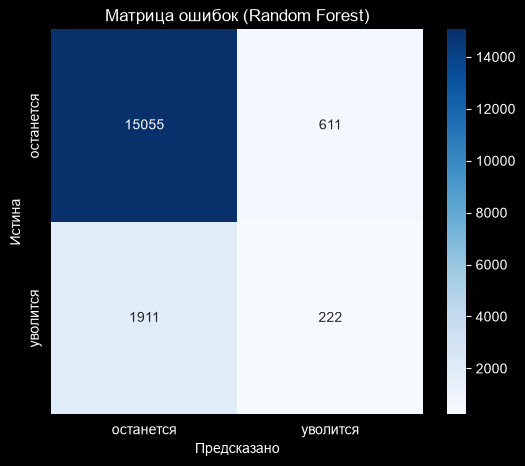

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['останется', 'уволится'],
            yticklabels=['останется', 'уволится'])
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title('Матрица ошибок (Random Forest)')
plt.show()

C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Порог для recall ≈ 0.5: 0.543
  Precision при этом пороге: 0.223
  Recall: 0.500


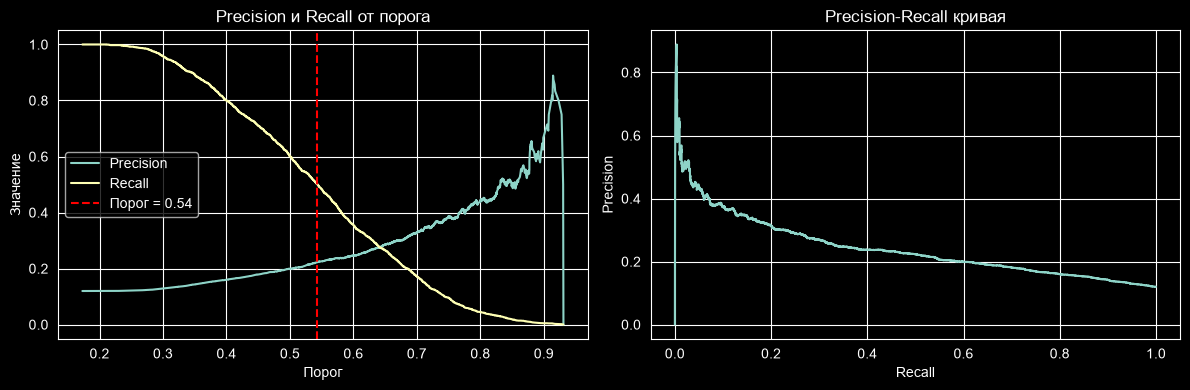


При пороге 0.5: recall = 0.601
При пороге 0.54: recall = 0.500


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_curve, recall_score

# Логистическая регрессия с балансировкой — предобработка внутри пайплайна
lr = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
])
lr.fit(X_train, y_train)
y_proba_lr = lr.predict_proba(X_test)[:, 1]

# Precision-Recall кривая
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_lr)

# Находим порог, близкий к recall = 0.5 (например)
target_recall = 0.5
idx = np.argmin(np.abs(recalls - target_recall))
optimal_threshold = thresholds[idx]

print(f"Порог для recall ≈ {target_recall}: {optimal_threshold:.3f}")
print(f"  Precision при этом пороге: {precisions[idx]:.3f}")
print(f"  Recall: {recalls[idx]:.3f}")

# Графики
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Порог = {optimal_threshold:.2f}')
plt.xlabel('Порог')
plt.ylabel('Значение')
plt.title('Precision и Recall от порога')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(recalls[:-1], precisions[:-1])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривая')
plt.grid(True)

plt.tight_layout()
plt.show()

# Применяем новый порог
y_pred_custom = (y_proba_lr >= optimal_threshold).astype(int)
print(f"\nПри пороге 0.5: recall = {recall_score(y_test, (y_proba_lr >= 0.5).astype(int)):.3f}")
print(f"При пороге {optimal_threshold:.2f}: recall = {recall_score(y_test, y_pred_custom):.3f}")

Порог: 0.65
Матрица ошибок:
[[14252  1414]
 [ 1567   566]]

TP (верно найдены увольнения): 566
FN (пропущены увольнения): 1567
FP (ложные тревоги): 1414
TN (верно предсказаны остались): 14252


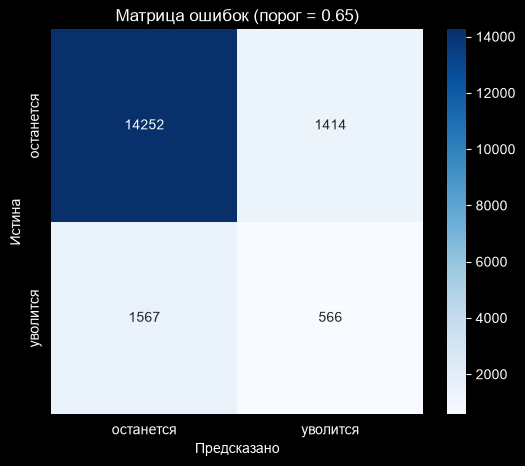

In [39]:
threshold_balanced = 0.65
y_pred_balanced = (y_proba_lr >= threshold_balanced).astype(int)

cm_balanced = confusion_matrix(y_test, y_pred_balanced)
tn, fp, fn, tp = cm_balanced.ravel()

print(f"Порог: {threshold_balanced}")
print(f"Матрица ошибок:")
print(cm_balanced)
print(f"\nTP (верно найдены увольнения): {tp}")
print(f"FN (пропущены увольнения): {fn}")
print(f"FP (ложные тревоги): {fp}")
print(f"TN (верно предсказаны остались): {tn}")

# Визуализация
plt.figure(figsize=(6, 5))
sns.heatmap(cm_balanced, annot=True, fmt='d', cmap='Blues',
            xticklabels=['останется', 'уволится'],
            yticklabels=['останется', 'уволится'])
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок (порог = {threshold_balanced})')
plt.show()

In [40]:
thresholds = [0.30, 0.50, 0.75]
results = []

for th in thresholds:
    y_pred_th = (y_proba_lr >= th).astype(int)
    results.append({
        'threshold': th,
        'precision': precision_score(y_test, y_pred_th),
        'recall': recall_score(y_test, y_pred_th),
        'f1': f1_score(y_test, y_pred_th),
        'tp': confusion_matrix(y_test, y_pred_th).ravel()[3]
    })

df_results = pd.DataFrame(results)
print(df_results.round(3))

   threshold  precision  recall     f1    tp
0       0.30      0.128   0.959  0.227  2045
1       0.50      0.199   0.601  0.299  1281
2       0.75      0.386   0.096  0.153   204


Порог: 0.5
Матрица ошибок:
[[10513  5153]
 [  852  1281]]

TP (верно найдены увольнения): 1281
FN (пропущены увольнения): 852
FP (ложные тревоги): 5153
TN (верно предсказаны остались): 10513


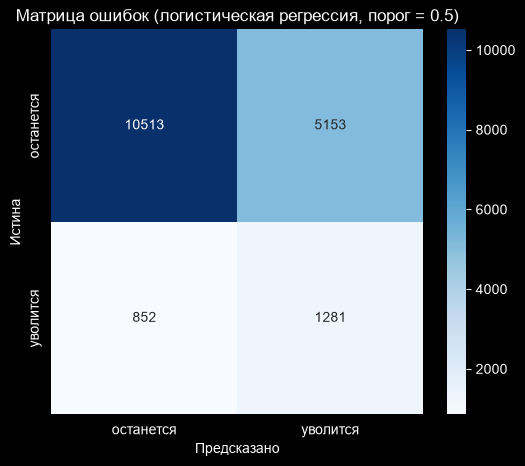

In [41]:
threshold = 0.50
y_pred_050 = (y_proba_lr >= threshold).astype(int)

cm_050 = confusion_matrix(y_test, y_pred_050)
tn, fp, fn, tp = cm_050.ravel()

print(f"Порог: {threshold}")
print(f"Матрица ошибок:")
print(cm_050)
print(f"\nTP (верно найдены увольнения): {tp}")
print(f"FN (пропущены увольнения): {fn}")
print(f"FP (ложные тревоги): {fp}")
print(f"TN (верно предсказаны остались): {tn}")

# Визуализация
plt.figure(figsize=(6, 5))
sns.heatmap(cm_050, annot=True, fmt='d', cmap='Blues',
            xticklabels=['останется', 'уволится'],
            yticklabels=['останется', 'уволится'])
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок (логистическая регрессия, порог = {threshold})')
plt.show()

Порог: 0.3
Матрица ошибок:
[[ 1793 13873]
 [   88  2045]]

TP (верно найдены увольнения): 2045
FN (пропущены увольнения): 88
FP (ложные тревоги): 13873
TN (верно предсказаны остались): 1793


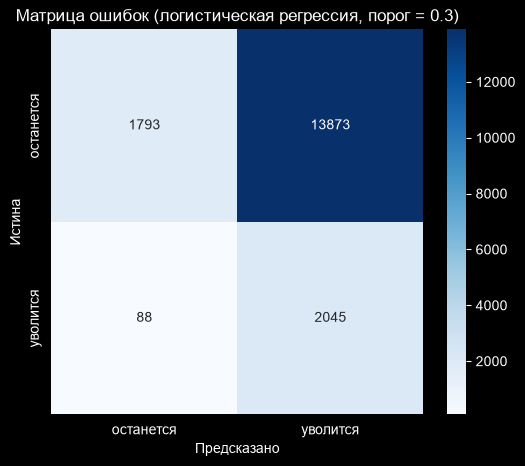

In [42]:
threshold = 0.30
y_pred_030 = (y_proba_lr >= threshold).astype(int)

cm_030 = confusion_matrix(y_test, y_pred_030)
tn, fp, fn, tp = cm_030.ravel()

print(f"Порог: {threshold}")
print(f"Матрица ошибок:")
print(cm_030)
print(f"\nTP (верно найдены увольнения): {tp}")
print(f"FN (пропущены увольнения): {fn}")
print(f"FP (ложные тревоги): {fp}")
print(f"TN (верно предсказаны остались): {tn}")

# Визуализация
plt.figure(figsize=(6, 5))
sns.heatmap(cm_030, annot=True, fmt='d', cmap='Blues',
            xticklabels=['останется', 'уволится'],
            yticklabels=['останется', 'уволится'])
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок (логистическая регрессия, порог = {threshold})')
plt.show()

Fitting 5 folds for each of 81 candidates, totalling 405 fits


C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Лучшие параметры: {'clf__max_depth': 10, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 10, 'clf__n_estimators': 300}
Лучший recall на CV: 0.5855

На тесте:
Precision: 0.2324
Recall: 0.5584
F1: 0.3282
ROC-AUC: 0.7112


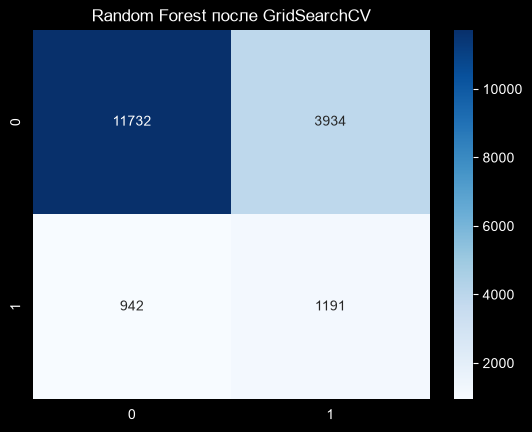

In [43]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Базовый Random Forest внутри пайплайна с preprocess_tree
rf_pipe = Pipeline([
    ('prep', preprocess_tree),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)),
])

# Сетка гиперпараметров — с префиксом clf__
param_grid = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [10, 20, None],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
}

# StratifiedKFold для учёта дисбаланса
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV (оптимизируем по recall)
grid_search = GridSearchCV(
    rf_pipe,
    param_grid,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший recall на CV: {grid_search.best_score_:.4f}")

# Оценка на тесте — best_estimator_ уже пайплайн, предобработка применяется сама
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print(f"\nНа тесте:")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1: {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.4f}")

# Матрица ошибок
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest после GridSearchCV')
plt.show()

# KNN + SMOTE

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

knn_pipe = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', KNeighborsClassifier(n_neighbors=5)),
])
knn_pipe.fit(X_train, y_train)
y_pred_knn = knn_pipe.predict(X_test)
y_proba_knn = knn_pipe.predict_proba(X_test)[:, 1]

print("KNN (preprocess_scaled, k=5):")
print(f"Precision: {precision_score(y_test, y_pred_knn):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_knn):.4f}")
print(f"F1: {f1_score(y_test, y_pred_knn):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_knn):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_knn):.4f}")

C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


KNN (preprocess_scaled, k=5):
Precision: 0.2646
Recall: 0.0530
F1: 0.0883
ROC-AUC: 0.5951
Balanced accuracy: 0.5165


In [37]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier

# Создаём ImbPipeline
pipeline_knn = Pipeline([
    ('prep', preprocess_scaled),        # 1. Кодирование + масштабирование (внутри CT)
    ('smote', SMOTE(random_state=42)),  # 2. Балансировка
    ('clf', KNeighborsClassifier()),    # 3. Модель
])

# Обучаем Pipeline
pipeline_knn.fit(X_train, y_train)
y_pred_pipeline = pipeline_knn.predict(X_test)
y_proba_pipeline = pipeline_knn.predict_proba(X_test)[:, 1]

print("\nKNN с ImbPipeline (preprocess_scaled + SMOTE):")
print(f"Precision: {precision_score(y_test, y_pred_pipeline):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_pipeline):.4f}")
print(f"F1: {f1_score(y_test, y_pred_pipeline):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_pipeline):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_pipeline):.4f}")

C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(



KNN с ImbPipeline (preprocess_scaled + SMOTE):
Precision: 0.1782
Recall: 0.3858
F1: 0.2438
ROC-AUC: 0.6048
Balanced accuracy: 0.5718


In [38]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Сетка гиперпараметров для KNN (префикс clf__, т.к. шаг называется 'clf')
param_dist = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
    'clf__weights': ['uniform', 'distance'],
    'clf__metric': ['euclidean', 'manhattan'],
}

# RandomizedSearchCV с ImbPipeline
random_search = RandomizedSearchCV(
    pipeline_knn,
    param_dist,
    n_iter=20,                      # количество случайных комбинаций
    cv=StratifiedKFold(5),
    scoring='recall',               # оптимизируем полноту
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

random_search.fit(X_train, y_train)

print(f"\nЛучшие параметры: {random_search.best_params_}")
print(f"Лучший recall на CV: {random_search.best_score_:.4f}")

# Оценка на тесте
best_pipeline = random_search.best_estimator_
y_pred_best = best_pipeline.predict(X_test)
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]

print(f"\nKNN с ImbPipeline и подбором параметров:")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_best):.4f}")
print(f"F1: {f1_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_best):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_best):.4f}")

# Матрица ошибок
cm_knn = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')
plt.title('KNN + ImbPipeline + RandomizedSearchCV')
plt.show()

Fitting 5 folds for each of 20 candidates, totalling 100 fits


C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(



Лучшие параметры: {'clf__weights': 'uniform', 'clf__n_neighbors': 11, 'clf__metric': 'euclidean'}
Лучший recall на CV: 0.5123

KNN с ImbPipeline и подбором параметров:
Precision: 0.1834
Recall: 0.4974
F1: 0.2680
ROC-AUC: 0.6335
Balanced accuracy: 0.5979


NameError: name 'confusion_matrix' is not defined

In [39]:
from sklearn.metrics import roc_curve, auc

# ROC-кривые
plt.figure(figsize=(10, 8))

# Логистическая регрессия (Pipeline: preprocess_scaled → LR)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})', linewidth=2)

# Random Forest (Pipeline: preprocess_tree → RF)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})', linewidth=2)

# KNN (ImbPipeline: preprocess_scaled → SMOTE → KNN)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_proba_best)
roc_auc_knn = auc(fpr_knn, tpr_knn)
plt.plot(fpr_knn, tpr_knn, label=f'KNN + ImbPipeline (AUC = {roc_auc_knn:.3f})', linewidth=2)

# Диагональная линия (случайное угадывание)
plt.plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые сравнения моделей')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

NameError: name 'y_proba_lr' is not defined

<Figure size 1000x800 with 0 Axes>

In [46]:
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

# ROC-AUC для логистической регрессии
roc_auc_lr = roc_auc_score(y_test, y_proba_lr)

# Предикты LR при пороге 0.30 (для таблицы)
y_pred_lr_030 = (y_proba_lr >= 0.30).astype(int)

# Собираем все результаты
results = pd.DataFrame({
    'Модель': ['Логистическая регрессия (порог 0.30)',
               'Random Forest (GridSearchCV)',
               'KNN + ImbPipeline (RandomizedSearchCV)'],
    'Precision': [precision_score(y_test, y_pred_lr_030),
                  precision_score(y_test, y_pred_rf),
                  precision_score(y_test, y_pred_best)],
    'Recall': [recall_score(y_test, y_pred_lr_030),
               recall_score(y_test, y_pred_rf),
               recall_score(y_test, y_pred_best)],
    'F1': [f1_score(y_test, y_pred_lr_030),
           f1_score(y_test, y_pred_rf),
           f1_score(y_test, y_pred_best)],
    'Balanced accuracy': [balanced_accuracy_score(y_test, y_pred_lr_030),
                          balanced_accuracy_score(y_test, y_pred_rf),
                          balanced_accuracy_score(y_test, y_pred_best)],
    'ROC-AUC': [roc_auc_lr, roc_auc_rf, roc_auc_knn]
})

print("=== СРАВНЕНИЕ МОДЕЛЕЙ ===\n")
print(results.round(4).to_string(index=False))

=== СРАВНЕНИЕ МОДЕЛЕЙ ===

                                Модель  Precision  Recall     F1  Balanced accuracy  ROC-AUC
  Логистическая регрессия (порог 0.30)     0.1285  0.9587 0.2266             0.5366   0.6842
          Random Forest (GridSearchCV)     0.2566  0.4308 0.3217             0.6305   0.7078
KNN + ImbPipeline (RandomizedSearchCV)     0.1834  0.4974 0.2680             0.5979   0.6335


In [47]:
from sklearn.metrics import fbeta_score

# Вычисляем F2 для каждой модели
f2_lr = fbeta_score(y_test, y_pred_lr_030, beta=2)
f2_rf = fbeta_score(y_test, y_pred_rf, beta=2)
f2_knn = fbeta_score(y_test, y_pred_best, beta=2)

# Обновляем таблицу
results['F2'] = [f2_lr, f2_rf, f2_knn]

print("=== СРАВНЕНИЕ МОДЕЛЕЙ (с F2) ===\n")
print(results.round(4).to_string(index=False))

=== СРАВНЕНИЕ МОДЕЛЕЙ (с F2) ===

                                Модель  Precision  Recall     F1  Balanced accuracy  ROC-AUC     F2
  Логистическая регрессия (порог 0.30)     0.1285  0.9587 0.2266             0.5366   0.6842 0.4182
          Random Forest (GridSearchCV)     0.2566  0.4308 0.3217             0.6305   0.7078 0.3793
KNN + ImbPipeline (RandomizedSearchCV)     0.1834  0.4974 0.2680             0.5979   0.6335 0.3705


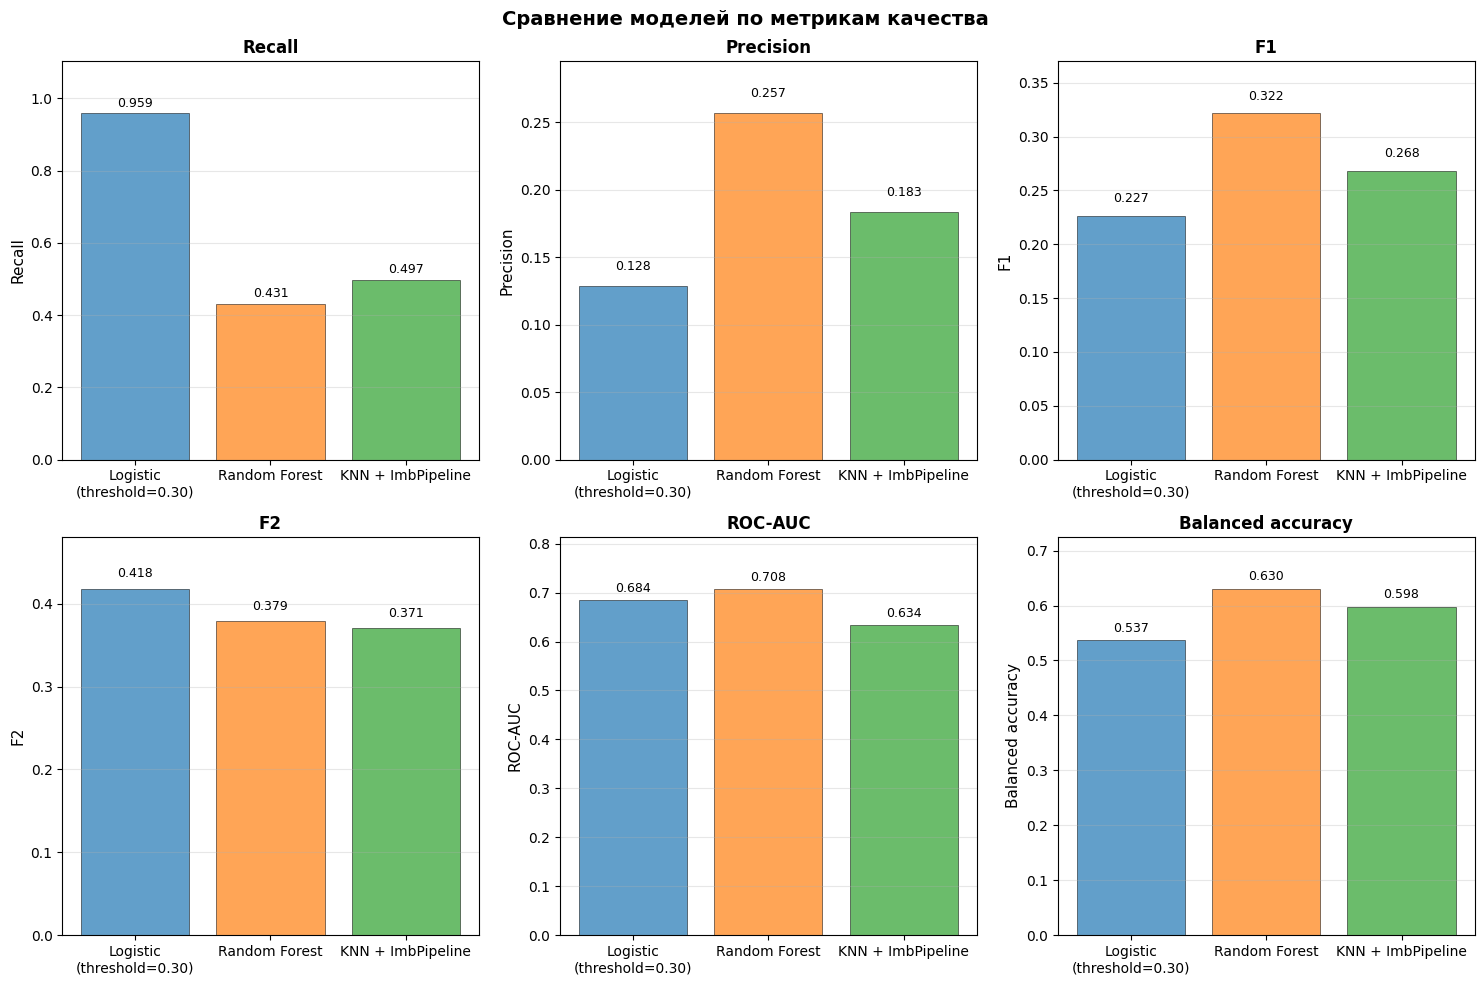

In [51]:
models = ['Logistic\n(threshold=0.30)', 'Random Forest', 'KNN + ImbPipeline']
metrics = ['Recall', 'Precision', 'F1', 'F2', 'ROC-AUC', 'Balanced accuracy']

# Берём значения прямо из таблицы results, чтобы график не расходился с расчётами
values = {m: results[m].tolist() for m in metrics}

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    bars = ax.bar(models, values[metric],
                  color=colors, alpha=0.7, edgecolor='black', linewidth=0.5)
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    # верхняя граница с запасом под максимум столбца
    ax.set_ylim(0, max(values[metric]) * 1.15)

    for bar, val in zip(bars, values[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Сравнение моделей по метрикам качества', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Семинар

In [44]:
df_school = pd.read_excel(DATA_DIR / 'Школы.xlsx')

In [46]:
df_school = df_school.rename(columns={
    "Школа": "school_num",
    "Округ": "district",
    "Кол-во зданий":  "building_num",
    "Общая численность контингента": "students_num"
})



In [47]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score, confusion_matrix)

In [49]:
df_pedagog_clean_schools = df_pedagog_clean[df_pedagog_clean["school_num"].isin(df_school["school_num"].copy())]

In [51]:
df_pedagog_clean_schools = df_pedagog_clean_schools.merge(df_school[["school_num", "district", "building_num", "students_num"]], on="school_num", how="inner")

In [59]:
FEATURES = [
    'school_num', 'sex', 'experience_age_pedagogic', 'class_manager',
    'main_position_cat', 'academic_degree_cat', 'category_qual_cat',
    'category_active', 'experience_age_other', 'n_unique_subjects',
    'min_parallel', 'max_parallel', 'n_unique_parallel', 'speciality_cat', "building_num", "students_num", "district",
]
# исключили 'category_date', 'id', 'year', 'is_out_next_year'

train = df_pedagog_clean_schools[df_pedagog_clean_schools['year'] == 2022]
test  = df_pedagog_clean_schools[df_pedagog_clean_schools['year'] == 2023]

X_train, y_train = train[FEATURES], train['is_out_next_year']
X_test,  y_test  = test[FEATURES],  test['is_out_next_year']

In [60]:
# где требуется только кодирование

preprocess_tree = ColumnTransformer([
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=5, random_state=42),
     ['school_num']),

    ('num', 'passthrough',
     ['sex', 'class_manager', 'experience_age_pedagogic', 'experience_age_other',
      'n_unique_subjects', 'min_parallel', 'max_parallel', 'n_unique_parallel', "building_num", "students_num"]),

    ('academic', academic_degree_step, ['academic_degree_cat']),

    ('qual', category_qual_grouped_step, ['category_qual_cat']),

    ('active', OrdinalEncoder(
        categories=[['не было', 'не активно', 'активно']],
        handle_unknown='use_encoded_value', unknown_value=-1,
    ), ['category_active']),

    ('ohe_position', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['main_position_cat']),
    ('ohe_speciality', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['speciality_cat']),
], remainder='drop', verbose_feature_names_out=False)

In [67]:
pipline_tree = Pipeline([
    ('prep', preprocess_tree),
    ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42)),
])
param_grid = {
    'clf__max_depth': [None, 5, 10, 15, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
}

grid_search = GridSearchCV(
    pipline_tree,
    param_grid,
    cv=StratifiedKFold(5),
    scoring='recall',
    n_jobs=-1,
    verbose=1,
)

In [68]:
grid_search.fit(X_train, y_train)
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший recall на CV: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 45 candidates, totalling 225 fits
Лучшие параметры: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Лучший recall на CV: 0.6535


C:\Users\User\PycharmProjects\hr-teachers\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(



На тесте:
Precision: 0.1945
Recall: 0.6716
F1: 0.3016
ROC-AUC: 0.6837


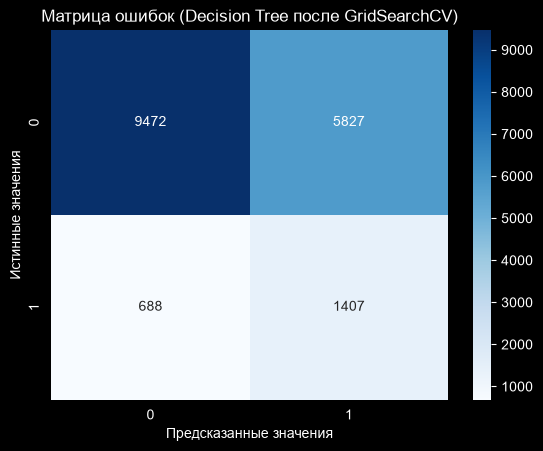

In [69]:
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print(f"\nНа тесте:")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1: {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.4f}")

# Матрица ошибок
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('Матрица ошибок (Decision Tree после GridSearchCV)')
plt.show()

In [71]:
roc_auc_score(y_test, y_proba_rf)

0.683689872565649